# 04 — Audit: dataset, channel quality and gate G0

**Stage question.** Is this corpus, as released, good enough to measure conversational delivery — and does it pass the specification's gate G0?

This is the first of the specification's three synthesis surfaces. It carries the corpus description, the channel-quality distributions, pitch-tracking reliability, feature droppage, the sample-attrition funnel, and the G0 verdict.

| | |
|---|---|
| **Purpose** | Describe the processed sample; show every channel-quality measure as a distribution; test the echo-suppression risk directly; measure how many pair turns can carry prosody; decide G0 against the specification's thresholds. |
| **Input** | `data/processed/channel_qc.parquet` and per-session tracks (notebook 03); `turns.parquet`, `pairs_candidates.parquet`, `transcript_vad_agreement.parquet` (notebook 02); the manifest. |
| **Processing** | Composition tables → objective failures → continuous quality measures by recording site → the double-talk (echo-suppression) check → octave-error profile → voiced frames per turn and droppage → complete funnel → G0. |
| **Output** | `results/audit/` (tables, funnel, G0 verdict as JSON), `docs/gates/G0.md`, `figures/04_audit/`. |
| **Scientific assumptions** | G0's thresholds are the specification's own (≥ 80% of channels usable, droppage < 15%). A channel is one participant file; droppage is the share of candidate-pair turns with fewer than 10 voiced frames (`configs/features.yaml`), the specification's "missing prosody". |
| **Failure modes** | Judging a continuous measure after seeing it and cutting there (not done: every continuous cut is listed with its reason); a pilot unrepresentative of the sample (compared in notebook 01); reading G0 as evidence about the hypotheses (it is not: it only says the instrument can be used). |
| **What to look at** | The objective-failure table, the overlap-attenuation distribution, the octave profile, the droppage by turn length, and the G0 block at the end. |

**Expectation recorded before this notebook was run:** 2026-09-23. Channel failures were expected to be rare. Droppage was flagged as the risk because of very short replies, and overlap attenuation from echo suppression as unknown.

**Terms used in this notebook.**

- **Channel** — one participant's audio file for one interaction.
- **SNR (signal-to-noise ratio)** — how far a speaker's speech level sits above the background level, in dB. Higher is cleaner.
- **Bleed** — the partner's voice leaking into a speaker's microphone. Measured as the speaker's channel level while only the partner talks, relative to the speaker's own speech. Strongly negative means little leakage.
- **Double talk / overlap** — both people speaking at once.
- **Overlap attenuation** — the speaker's own channel level during double talk, relative to their speech alone. Echo suppression that gates the speaker's voice in double talk shows up as a strongly negative value. It would distort intensity and create silences that are not pauses.
- **Voiced frame** — a 10 ms frame where the pitch tracker found a periodic voice signal.
- **Octave error** — a pitch estimate at half or double the true value.
- **Feature droppage** — the share of turns whose prosody cannot be measured, here because they have fewer than 10 voiced frames (0.1 s of voicing).

In [1]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   11.9 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint e1a10dc2c7145664
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=293, channel_qc=True


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [2]:
# Parameters
STAGE = 'sample'               # which processed set to audit: 'pilot' or 'sample'

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FeatureConfig
from src.paths import paths
from src.features.prosody import turn_voicing, feature_droppage
from src.preprocessing.channel_qc import (g0_verdict, relative_log2_f0, usable_interactions,
                                          QC_OBJECTIVE_FAILURES)
from src.runtime import write_run_record
from src.viz import style

P = paths().ensure()
CFG = P.load_config('corpus')
FCFG = FeatureConfig()
VARIANT = FCFG.pitch_segment_source
# Outputs are keyed by the measurement variant, so a re-measurement never
# overwrites an earlier verdict. The unsuffixed files in results/audit/ are the
# first pilot run, measured over voice activity alone.
TAG = f'{STAGE}__{VARIANT}'
FIGDIR = f'04_audit__{TAG}'
style.apply()
OUT = P.results / 'audit'
OUT.mkdir(parents=True, exist_ok=True)
(P.root / 'docs' / 'gates').mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(P.manifest, dtype=str)
selected = pd.read_csv(P.results / 'acquisition' / f'selected_sessions_{STAGE}.csv')
sessions = set(selected['session_key'])
qc = pd.read_parquet(P.processed / 'channel_qc.parquet')
qc = qc[qc['session_key'].isin(sessions)].copy()
turns = pd.read_parquet(P.processed / 'turns.parquet')
turns = turns[turns['session_key'].isin(sessions)]
pairs = pd.read_parquet(P.processed / 'pairs_candidates.parquet')
pairs = pairs[pairs['session_key'].isin(sessions)]
agree = pd.read_parquet(P.processed / 'transcript_vad_agreement.parquet')
print(f"auditing stage {STAGE}: {len(sessions)} sessions, {qc['interaction_key'].nunique()} interactions, "
      f"{len(qc)} channels")
print(f"pitch analysed over: {VARIANT}   (outputs tagged '{TAG}')")
if 'analysed_speech_s' in qc.columns and qc['analysed_speech_s'].notna().any():
    added = qc['analysed_speech_s'].sum() - qc['vad_only_speech_s'].sum()
    print(f"speech analysed: {qc['analysed_speech_s'].sum() / 3600:.1f} h, of which "
          f"{added / 3600:.1f} h ({added / qc['analysed_speech_s'].sum():.1%}) comes from "
          f"transcript regions the voice-activity detector missed")

auditing stage sample: 250 sessions, 2882 interactions, 5764 channels
pitch analysed over: vad_plus_transcript   (outputs tagged 'sample__vad_plus_transcript')
speech analysed: 146.0 h, of which 18.8 h (12.9%) comes from transcript regions the voice-activity detector missed


## 1. The processed sample

In [4]:
ok = qc[qc['failure'].isna()]
comp = pd.Series({
    'sessions (dyads)': len(sessions),
    'speakers': qc['participant_key'].nunique(),
    'interactions': qc['interaction_key'].nunique(),
    'channels': len(qc),
    'recording sites': qc['vendor_id'].nunique(),
    'audio hours (both channels)': round(qc['duration_s'].sum() / 3600, 1),
    'conversation hours': round(qc['duration_s'].sum() / 3600 / 2, 1),
    'own-speech hours (VAD)': round(qc['vad_speech_s'].sum() / 3600, 1),
    'timed words': int(qc['n_words_timed'].sum()),
    'turns': int((~turns['embedded']).sum()),
    'candidate pairs': len(pairs),
}, name=STAGE)
comp.to_frame().to_csv(OUT / f'composition_{TAG}.csv')
comp.to_frame()

,sample
sessions (dyads),250.0
speakers,500.0
interactions,2882.0
channels,5764.0
recording sites,4.0
audio hours (both channels),321.4
conversation hours,160.7
own-speech hours (VAD),127.9
timed words,1614916.0
turns,108837.0


## 2. Objective failures

Defects that make a channel unusable regardless of judgement : missing or unreadable file, wrong sample rate, not mono, a duration that disagrees with the partner's file by more than half a second, no detected speech, no timed words. An interaction needs both channels; a session needs at least one usable interaction.

In [5]:
fail = qc['failure'].fillna('none').value_counts().reindex(['none', *QC_OBJECTIVE_FAILURES], fill_value=0)
inter = usable_interactions(qc)
tab = pd.DataFrame({'channels': fail})
tab.to_csv(OUT / f'objective_failures_{TAG}.csv')
display(tab)
print(f"channel pass rate: {(qc['failure'].isna()).mean():.1%}")
print(f"usable interactions: {int(inter.sum())} of {inter.size}")
print(f"largest duration mismatch between partner files: {qc['pair_duration_mismatch_s'].max():.3f} s")
print(f"sample rates seen: {sorted(qc['sample_rate'].dropna().unique().tolist())}; "
      f"formats: {sorted(qc['subtype'].dropna().unique().tolist())}")

,channels
failure,
none,5600
missing,0
unreadable,0
wrong_sample_rate,0
not_mono,0
duration_mismatch,0
no_vad_speech,136
no_timed_words,2


channel pass rate: 97.2%
usable interactions: 2778 of 2882
largest duration mismatch between partner files: 0.000 s
sample rates seen: [48000]; formats: ['FLOAT']


**Reading it.** The duration check doubles as the check that both files of an interaction share a time origin, which turn construction assumes. The format line confirms the audio as delivered, which differs from the dataset card's statement of 16-bit.

## 3. Continuous channel-quality measures, by recording site

These are reported, not cut on. The four recording sites differ in equipment and room, so each measure is shown per site.

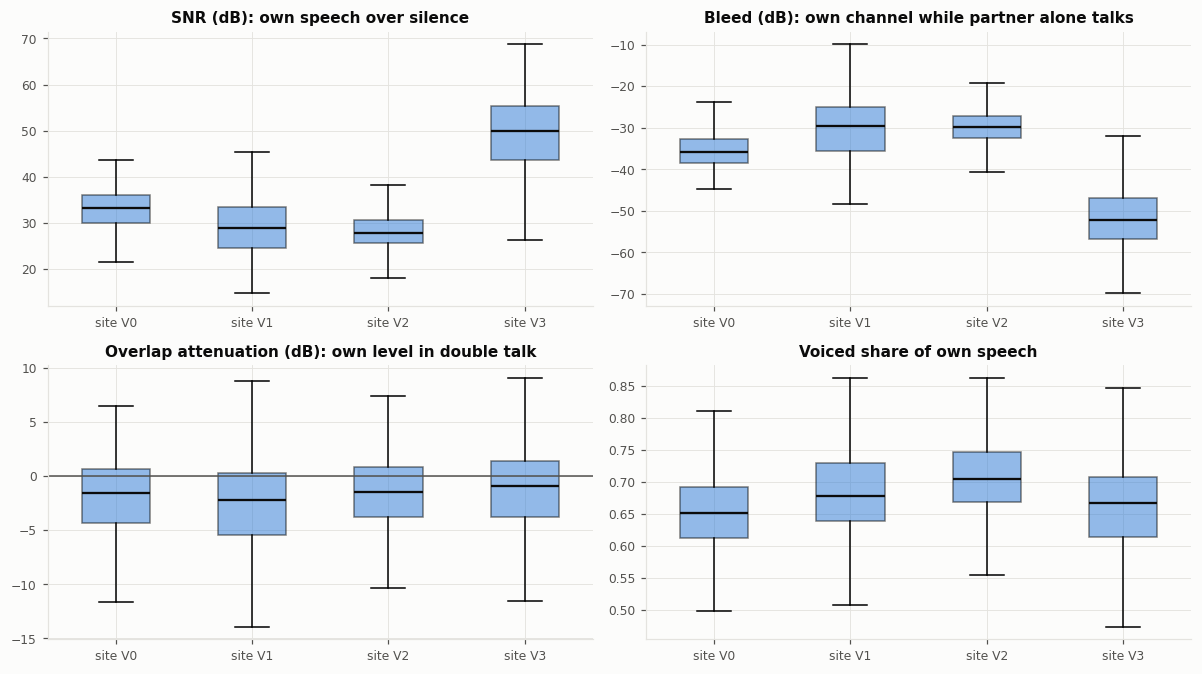

,snr_db,bleed_db,overlap_drop_db,voiced_frac_own_speech,flat_top_runs,channels,share with flat-top runs
vendor_id,,,,,,,
0,33.25,-35.87,-1.61,0.65,0.0,632,0.000
1,28.90,-29.57,-2.24,0.68,3.0,771,0.645
2,27.77,-29.77,-1.48,0.70,0.0,1225,0.009
3,49.94,-52.28,-0.89,0.67,0.0,2972,0.044


In [6]:
measures = [('snr_db', 'SNR (dB): own speech over silence'),
            ('bleed_db', 'Bleed (dB): own channel while partner alone talks'),
            ('overlap_drop_db', 'Overlap attenuation (dB): own level in double talk'),
            ('voiced_frac_own_speech', 'Voiced share of own speech')]
sites = sorted(ok['vendor_id'].unique())
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
for ax, (col, title) in zip(axes.ravel(), measures):
    data = [ok.loc[ok['vendor_id'] == s, col].dropna() for s in sites]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops={'color': style.INK, 'linewidth': 1.5})
    for patch in bp['boxes']:
        patch.set_facecolor(style.SERIES[0])
        patch.set_alpha(0.5)
    ax.set_xticks(range(1, len(sites) + 1), [f'site V{s}' for s in sites])
    ax.set_title(title, fontsize=10)
    if col == 'overlap_drop_db':
        ax.axhline(0, color=style.INK_SECONDARY, linewidth=1)
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'channel_quality_by_site')
plt.show()
by_site = ok.groupby('vendor_id')[[m for m, _ in measures] + ['flat_top_runs']].median().round(2)
by_site['channels'] = ok.groupby('vendor_id').size()
by_site['share with flat-top runs'] = ok.groupby('vendor_id')['flat_top_runs'].apply(lambda s: (s > 0).mean()).round(3)
by_site.to_csv(OUT / f'channel_quality_by_site_{TAG}.csv')
by_site

**What is plotted.** For each recording site, the spread of four channel measures across usable channels (box = middle half, line = median, whiskers = the bulk of the data).

**Why it matters.**
- *SNR* says whether speech stands clear of the background, which pitch and intensity need.
- *Bleed* says whether a channel carries only its own speaker. If the partner leaks in, "the reply's delivery" is partly the partner's, and the coupling the study measures would be built into the measurement.
- *Overlap attenuation* is the echo-suppression test, examined in section 4.
- *Voiced share of own speech* is how much of detected speech the pitch tracker can use.

**What would indicate a problem.** Bleed near 0 dB, meaning the partner is as loud on a channel as its own speaker. SNR near 0 dB. A site whose voiced share is far below the others. Flat-top runs (clipping) on a large share of channels.

**Conclusion.** Record the medians per site from the table. A site that stands apart is a candidate for a stratified robustness check later, not for exclusion now. Excluding a site after seeing its numbers would be a post hoc cut.

## 4. The echo-suppression check: what happens to a speaker's own voice in double talk?

The released audio passed through echo suppression to remove each partner's voice from the other's microphone. Such algorithms can also attenuate a speaker's *own* voice while both are talking. If they do, the speaker's intensity is under-measured exactly when replies overlap their partner, and gated stretches look like pauses.

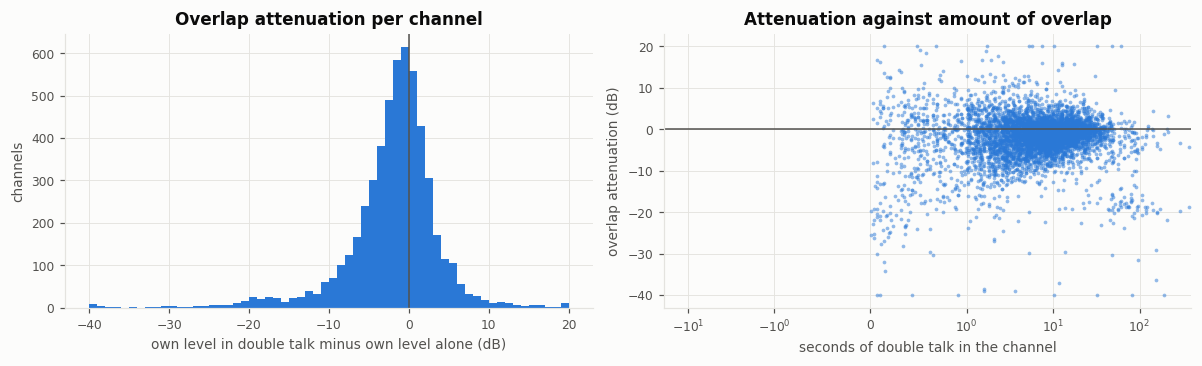

overlap attenuation quantiles (dB): {0.05: -12.2, 0.25: -4.1, 0.5: -1.3, 0.75: 1.0, 0.95: 5.3}
channels with any double talk: 5330 of 5600; double talk as share of own speech: 13.4%


In [7]:
od = ok['overlap_drop_db'].dropna()
w = ok.loc[od.index, 'overlap_s']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.hist(od.clip(-40, 20), bins=np.linspace(-40, 20, 61), color=style.SERIES[0])
ax.axvline(0, color=style.INK_SECONDARY, linewidth=1)
ax.set_xlabel('own level in double talk minus own level alone (dB)')
ax.set_ylabel('channels')
ax.set_title('Overlap attenuation per channel')
ax = axes[1]
ax.scatter(w, od.clip(-40, 20), s=6, color=style.SERIES[0], alpha=0.5)
ax.axhline(0, color=style.INK_SECONDARY, linewidth=1)
ax.set_xscale('symlog', linthresh=1)
ax.set_xlabel('seconds of double talk in the channel')
ax.set_ylabel('overlap attenuation (dB)')
ax.set_title('Attenuation against amount of overlap')
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'overlap_attenuation')
plt.show()
q = od.quantile([.05, .25, .5, .75, .95]).round(1)
print('overlap attenuation quantiles (dB):', q.to_dict())
print(f"channels with any double talk: {int((ok['overlap_s'] > 0).sum())} of {len(ok)}; "
      f"double talk as share of own speech: {ok['overlap_s'].sum() / ok['vad_speech_s'].sum():.1%}")

**What is plotted.** Left: per channel, the speaker's median frame level during double talk minus their median level when speaking alone. Right: the same against how much double talk the channel contains; estimates from channels with little overlap are noisy.

**How to read it.** Speech in double talk is not expected to be exactly as loud as speech alone: people raise or drop their voices when overlapping, and overlaps are often short backchannels. So a spread around a few dB either side of zero is ordinary conversational behaviour. Systematic gating looks different: a large block of channels well below zero, many decibels down, concentrated where there is plenty of overlap to estimate from.

**What would indicate a problem.** A median far below zero, or a distinct mode of strongly attenuated channels.

**What follows.** If attenuation is systematic, the preregistered fallback applies (literature survey): intensity-range and pause measures are computed on non-overlapped regions only. That choice is made on this evidence, before any target is fitted, and recorded as a decision. If attenuation is not systematic, the measures are computed as specified.

## 5. Pitch-tracking reliability

Two views. The octave profile pools every voiced frame of every usable channel, relative to that channel's own median. Pitch-tracking errors that halve or double the estimate appear as bumps one octave below or above the main mass. The second view is the voiced share of own speech, per channel.

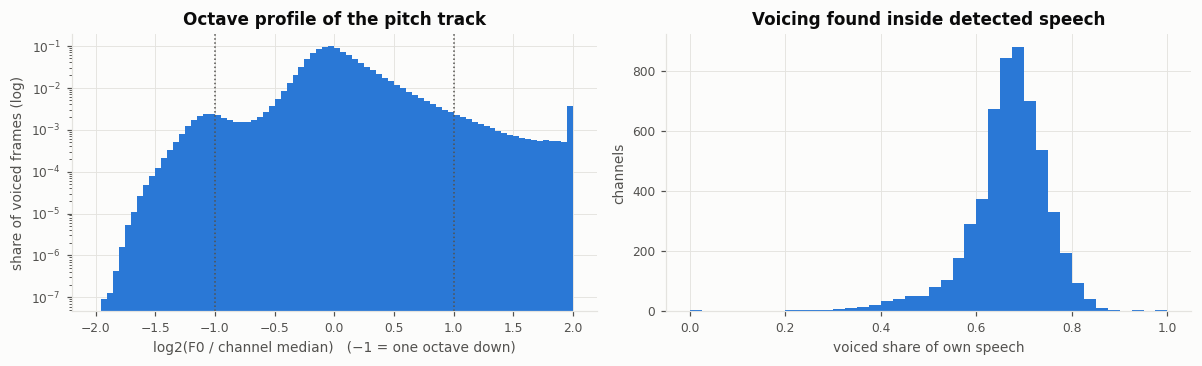

mean share of voiced frames more than 0.75 octave below the channel median: 2.21%; above: 4.29%


In [8]:
counts, bins, per_file = relative_log2_f0(P, qc)
per_file.to_csv(OUT / f'octave_profile_per_channel_{TAG}.csv', index=False)
centres = (bins[:-1] + bins[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(centres, counts / counts.sum(), width=bins[1] - bins[0], color=style.SERIES[0])
ax.set_yscale('log')
for x in (-1, 1):
    ax.axvline(x, color=style.INK_SECONDARY, linewidth=1, linestyle=':')
ax.set_xlabel('log2(F0 / channel median)   (−1 = one octave down)')
ax.set_ylabel('share of voiced frames (log)')
ax.set_title('Octave profile of the pitch track')
ax = axes[1]
ax.hist(ok['voiced_frac_own_speech'].dropna(), bins=np.linspace(0, 1, 41), color=style.SERIES[0])
ax.set_xlabel('voiced share of own speech')
ax.set_ylabel('channels')
ax.set_title('Voicing found inside detected speech')
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'pitch_reliability')
plt.show()
low = per_file['share_below_minus_0_75'].mean()
high = per_file['share_above_plus_0_75'].mean()
print(f"mean share of voiced frames more than 0.75 octave below the channel median: {low:.2%}; above: {high:.2%}")

**What is plotted.** Left: every voiced frame's pitch relative to its own channel's median, in octaves, on a log vertical scale so the rare tails are visible. Right: per channel, the share of detected speech in which a pitch was found.

**Why it matters.** The pitch-span target is the 5th-to-95th-percentile range of log-F0 in a turn. Halving errors sit exactly in the lower tail that the 5th percentile reads. Voiced share determines how many turns can be measured at all.

**What would indicate a problem.** A visible secondary bump near −1 or +1 containing more than a small fraction of frames. A mass of channels with near-zero voicing, which would be a tracking failure rather than a property of speech; about 40–60% of speech time is typically voiced.

**What follows.** The 0.75-octave figure is descriptive and is not applied as a filter. Whether the pitch range should be adapted per speaker is a measurement decision for the prosody-targets stage. Examples are the two-pass method of setting floor and ceiling from each speaker's own distribution, or the speaker-sex-specific ranges used in the entrainment literature the target set is drawn from. That decision will be recorded before any target is fitted. The evidence for it is this figure.

## 6. Feature droppage — the second G0 criterion

For every turn that appears in a candidate pair, count the voiced frames inside it. A turn with fewer than 10 (`configs/features.yaml`) cannot carry pitch measures and is dropped. Droppage is the share of such turns. Pair loss is reported beside it: a pair is lost if either of its turns is dropped.

,sample
turns_considered,108826.000000
turns_dropped,6291.000000
turn_droppage,0.057808
pairs_considered,105993.000000
pairs_lost,11557.000000
pair_loss,0.109036


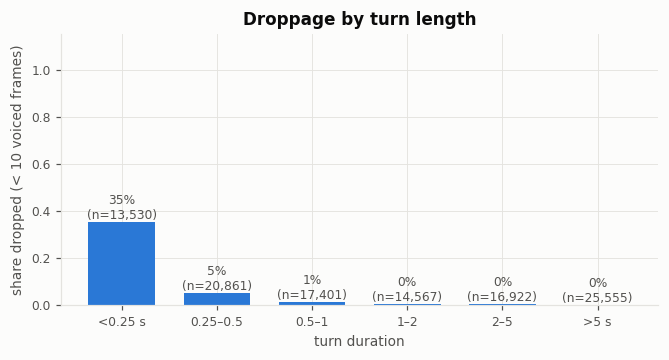

In [9]:
voicing = turn_voicing(turns[~turns['embedded']], P)
voicing.to_parquet(P.processed / 'turn_voicing.parquet', index=False)
drop = feature_droppage(pairs, voicing, FCFG.min_voiced_frames)
display(pd.Series(drop).to_frame(STAGE))

v = voicing[voicing['has_tracks']].merge(turns[['turn_id', 'duration', 'n_words']], on='turn_id')
v['length'] = pd.cut(v['duration'], [0, 0.25, 0.5, 1, 2, 5, 1e9],
                     labels=['<0.25 s', '0.25–0.5', '0.5–1', '1–2', '2–5', '>5 s'])
by_len = v.groupby('length', observed=True).agg(
    turns=('turn_id', 'size'),
    dropped=('voiced_frames', lambda s: (s < FCFG.min_voiced_frames).mean()))
by_len.to_csv(OUT / f'droppage_by_turn_length_{TAG}.csv')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_len.index.astype(str), by_len['dropped'], color=style.SERIES[0], width=0.7)
for x, (d, n) in enumerate(zip(by_len['dropped'], by_len['turns'])):
    ax.text(x, d, f'{d:.0%}\n(n={n:,})', ha='center', va='bottom', fontsize=8, color=style.INK_SECONDARY)
ax.set_ylim(0, 1.15)
ax.set_xlabel('turn duration')
ax.set_ylabel('share dropped (< 10 voiced frames)')
ax.set_title('Droppage by turn length')
style.save(fig, P.figures, FIGDIR, 'droppage_by_length')
plt.show()

**What is plotted.** The share of candidate-pair turns with too little voicing to measure, by turn duration, with the number of turns in each group.

**Why it matters.** Droppage is a G0 criterion, and its source matters as much as its size. If only very short turns ("yeah", "mm") are lost, the loss removes a known, describable class of replies. If long turns are also lost, the pitch tracker is failing on real speech, which is a measurement problem.

**What would indicate a problem.** Droppage well above zero for turns longer than a second. That would point to tracking failure or to missing voice-activity segments, as seen in notebook 03.

**What follows.** The specification requires that droppage is not condition-dependent. That check is run when conditions exist (the donor-assignment stage). The class of turns lost here is recorded now so it can be checked there.

## 7. The complete funnel

From the selected sessions to pairs whose two turns can both carry prosody and that have an N2 donor. This table is the sample-attrition record the report carries.

In [10]:
usable_ints = set(inter[inter].index)
p_ok = pairs[pairs['interaction_key'].isin(usable_ints)]
vv = voicing.set_index('turn_id')
meas = vv['has_tracks'] & (vv['voiced_frames'].fillna(0) >= FCFG.min_voiced_frames)
both = p_ok['partner_turn_id'].map(meas).fillna(False) & p_ok['reply_turn_id'].map(meas).fillna(False)
funnel = pd.DataFrame([
    ('selected sessions', len(sessions)),
    ('sessions with a usable interaction', int(selected['usable'].sum())),
    ('interactions', qc['interaction_key'].nunique()),
    ('interactions with both channels usable', len(usable_ints)),
    ('turns (embedded set aside)', int((~turns['embedded']).sum())),
    ('candidate pairs', len(pairs)),
    ('candidate pairs in usable interactions', len(p_ok)),
    ('pairs with both turns measurable', int(both.sum())),
    ('... and an N2 donor in the interaction', int((both & (p_ok['n2_candidates'] > 0)).sum())),
], columns=['step', 'count'])
funnel.to_csv(OUT / f'funnel_{TAG}.csv', index=False)
funnel

,step,count
0,selected sessions,250
1,sessions with a usable interaction,250
2,interactions,2882
3,interactions with both channels usable,2778
4,turns (embedded set aside),108837
5,candidate pairs,105993
6,candidate pairs in usable interactions,104941
7,pairs with both turns measurable,93498
8,... and an N2 donor in the interaction,89112


**Reading the funnel.** The last row is the number of pairs that can enter every comparison the design makes: the real partner turn, the N1 cross-dyad donor (always available within a split) and the N2 within-interaction donor. The unit of inference is still the session. This count sets the precision of estimates within sessions, and the number of sessions sets the effective sample size.

## 8. Comparing measurement variants

Gate G0 was first run with speech regions taken from the voice-activity detector alone, and it failed on droppage at 17.6%. The diagnosis (2026-09-24) found turns of a second and longer receiving almost no pitch where the detector had missed documented speech. The repair adds the transcript's own speech regions.

If an earlier verdict is on disk, both are shown here. **Neither replaces the other.** The first result stands in the record; what follows is a second measurement of the same audio under a stated, timestamped change to the instrument.

In [11]:
prev_paths = sorted(OUT.glob(f'G0_{STAGE}*.json'))
prev = []
for f in prev_paths:
    d = json.loads(f.read_text())
    d['file'] = f.name
    d.setdefault('pitch_segment_source', 'vad')
    prev.append(d)
if prev:
    cmp = pd.DataFrame(prev)[['file', 'pitch_segment_source', 'channel_pass_rate',
                              'feature_droppage', 'pair_loss', 'passed']]
    display(cmp.style.format({'channel_pass_rate': '{:.1%}', 'feature_droppage': '{:.2%}',
                              'pair_loss': '{:.1%}'}))

old_drop = OUT / f'droppage_by_turn_length_{STAGE}.csv'
if old_drop.exists():
    o = pd.read_csv(old_drop).set_index('length')
    side = by_len.join(o['dropped'].rename('dropped_before'), how='left')
    side = side.rename(columns={'dropped': 'dropped_now'})
    side['recovered'] = side['dropped_before'] - side['dropped_now']
    display(side.style.format({'dropped_now': '{:.1%}', 'dropped_before': '{:.1%}',
                               'recovered': '{:+.1%}', 'turns': '{:,.0f}'}))

In [12]:
# Is the newly recovered voicing real speech, or noise promoted to speech?
old_oct = OUT / f'octave_profile_per_channel_{STAGE}.csv'
if old_oct.exists() and VARIANT != 'vad':
    o = pd.read_csv(old_oct)
    cmp_oct = pd.DataFrame({
        'voice activity only': [o['voiced_frames'].sum(),
                                o['share_below_minus_0_75'].mean(),
                                o['share_above_plus_0_75'].mean()],
        'plus transcript': [per_file['voiced_frames'].sum(),
                            per_file['share_below_minus_0_75'].mean(),
                            per_file['share_above_plus_0_75'].mean()],
    }, index=['voiced frames', 'mean share > 0.75 octave below median',
              'mean share > 0.75 octave above median'])
    cmp_oct['change'] = cmp_oct['plus transcript'] - cmp_oct['voice activity only']
    display(cmp_oct)
    base = cmp_oct.loc['voiced frames', 'voice activity only']
    print(f"voiced frames added: {cmp_oct.loc['voiced frames', 'change']:,.0f} "
          f"({cmp_oct.loc['voiced frames', 'change'] / base:+.1%})")

**Reading the comparison.** The repair is monotone by construction: adding a second source of speech regions can only widen what is analysed, so droppage can only fall or stay level. Two things decide whether that fall is a repair or a new fault.

*Where the recovery lands.* Turns of a second and longer are the defect being fixed, and recovery should be clear there. Shorter turns may also recover, and legitimately so, because the voice-activity detector misses speech at every length; that on its own is not a warning sign.

*Whether the recovered frames are real speech.* This is the check that matters, and the octave table above is where to look. Analysing a region on its own sets Praat's silence threshold from that region's own loudest point, so a region that is mostly silence has a low reference and can let noise through as voicing. Spurious voicing of that kind does not behave like a voice: it scatters, and it shows up as a rising share of frames sitting more than three-quarters of an octave from the channel's median pitch. A large gain in voiced frames with those shares roughly unchanged means genuine speech was recovered. A gain together with a clear rise in them means noise is being promoted to speech, and the repair should be rejected rather than kept.

## 9. Gate G0

In [13]:
# G0 is decided on the complete pilot only: a verdict on part of it would be a
# different test from the one the specification defines.
expected = CFG['pilot_n_conversations'] if STAGE == 'pilot' else CFG['n_conversations']
complete = (len(sessions) == expected) if STAGE == 'pilot' else (int(selected['usable'].sum()) >= expected)
verdict = g0_verdict(qc, drop['turn_droppage'], CFG['channel_qc']['min_channel_pass_rate'],
                     CFG['channel_qc']['max_feature_droppage'])
if not complete:
    verdict['passed'] = None
    print(f"INCOMPLETE: {len(sessions)} of {expected} sessions processed. "
          "No verdict is issued; finish notebook 03 and rerun.")
verdict.update({'complete': complete, 'pitch_segment_source': VARIANT, 'stage': STAGE, 'sessions': len(sessions), 'pair_loss': drop['pair_loss'],
                'droppage_definition': f"share of candidate-pair turns with < {FCFG.min_voiced_frames} voiced frames"})
(OUT / f'G0_{TAG}.json').write_text(json.dumps(verdict, indent=2))
print(json.dumps(verdict, indent=2))

{
  "channels": 5764,
  "channel_pass_rate": 0.9715475364330326,
  "feature_droppage": 0.057807876794148456,
  "min_pass_rate": 0.8,
  "max_droppage": 0.15,
  "passed": true,
  "on_failure": "switch the primary corpus to AMI two-party stretches",
  "complete": true,
  "pitch_segment_source": "vad_plus_transcript",
  "stage": "sample",
  "sessions": 250,
  "pair_loss": 0.10903550234449445,
  "droppage_definition": "share of candidate-pair turns with < 10 voiced frames"
}


In [14]:
status = {True: 'PASS', False: 'FAIL', None: 'NOT ISSUED (stage incomplete)'}[verdict['passed']]
g0_md = f"""# Gate G0 — corpus and target viability ({STAGE})

**Verdict: {status}.**

| Criterion | Required | Observed |
|---|---|---|
| Channels usable | ≥ {verdict['min_pass_rate']:.0%} | {verdict['channel_pass_rate']:.1%} of {verdict['channels']} |
| Feature droppage | < {verdict['max_droppage']:.0%} | {verdict['feature_droppage']:.1%} |

- Sample: {len(sessions)} sessions, stage `{STAGE}`, selection seed {CFG['selection_seed']}.
- Speech regions for pitch: `{VARIANT}`.
- Droppage is the {verdict['droppage_definition']}; pairs lost because either turn is unmeasurable: {drop['pair_loss']:.1%}.
- On failure the specification switches the primary corpus to AMI two-party stretches; a configuration change, not a redesign.
- The expectation for this gate was recorded before it was run (2026-09-23).
- Evidence: `results/audit/` and `figures/04_audit/`, produced by `notebooks/04_audit.ipynb`.
"""
(P.root / 'docs' / 'gates' / f'G0_{TAG}.md').write_text(g0_md, encoding='utf-8')
print(g0_md)

# Gate G0 — corpus and target viability (sample)

**Verdict: PASS.**

| Criterion | Required | Observed |
|---|---|---|
| Channels usable | ≥ 80% | 97.2% of 5764 |
| Feature droppage | < 15% | 5.8% |

- Sample: 250 sessions, stage `sample`, selection seed 20260912.
- Speech regions for pitch: `vad_plus_transcript`.
- Droppage is the share of candidate-pair turns with < 10 voiced frames; pairs lost because either turn is unmeasurable: 10.9%.
- On failure the specification switches the primary corpus to AMI two-party stretches; a configuration change, not a redesign.
- The expectation for this gate was recorded before it was run (2026-09-23).
- Evidence: `results/audit/` and `figures/04_audit/`, produced by `notebooks/04_audit.ipynb`.



## 10. Items that need a decision before the prosody targets are computed

Nothing below has been applied. Each item is a measurement decision the evidence above bears on. It must be settled and recorded, with the evidence cited, before any of the eight target dimensions is fitted, because afterwards it could no longer be separated from its effect on the results.

1. **Overlap attenuation (section 4).** Compute intensity range and pause measures on all of each turn, or on non-overlapped regions only. The first pilot run measured a median attenuation of −1.0 dB with a quartile range of −3.8 to +1.0 dB, which is consistent with people speaking more quietly in overlap rather than with the suppression removing their voice; the 5th percentile of −13.4 dB shows a minority of channels where it does bite.
2. **Pitch range (section 5).** Keep the fixed 75–500 Hz range, or adapt floor and ceiling per speaker, if the octave profile shows a material halving bump.
3. **Voice activity missing quiet speech (notebook 03 example).** Pitch is measured only inside detected speech. If droppage by length shows long turns being lost, the per-segment analysis window is the place to look.
4. **Any continuous channel cut** (SNR, bleed, voiced share). None is applied. A cut would need a justification that does not come from these distributions alone.

In [15]:
rec = write_run_record(OUT / f'04_run_record_{TAG}.json', '04_audit', {
    'stage': STAGE, 'g0': verdict, 'funnel': dict(zip(funnel['step'], funnel['count'].astype(int))),
})
print('run record written')

run record written


## Summary

The G0 block above gives the verdict against the specification's own thresholds. The funnel gives the attrition from selected sessions to fully usable pairs. The four open measurement items are listed with the evidence each one depends on.

**On re-measurement.** Where a variant comparison appears above, both verdicts are part of the record and both are reported. A gate passed by a narrow margin after a change made in response to its failure is weak evidence of viability, however sound the reasoning behind the change, and is stated as such rather than presented as a clean pass.

**What G0 does not establish.** Anything about the hypotheses. It establishes only that the instrument can be applied to this corpus: channels are clean enough, and enough turns carry measurable prosody. Calibration of the instrument itself is gates G1 and G2.

**Next.** Once the items in section 9 are decided and recorded, the pair, split and firewall stage builds the speaker-disjoint splits over the usable sessions.